In [93]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [94]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [95]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [96]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [97]:
df.shape

(7043, 21)

In [98]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [99]:
df["TotalCharges"].str.strip().eq("").sum()

np.int64(11)

In [100]:
df[df["TotalCharges"].str.strip()== ""]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [101]:
df.loc[
    df["TotalCharges"].str.strip() == "",
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [102]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'],errors="coerce")

In [103]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [104]:
df['TotalCharges']= df['TotalCharges'].fillna(0)

In [105]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [106]:
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


In [107]:
df['Churn'].value_counts(normalize=True) * 100

,proportion
Churn,
No,73.463013
Yes,26.536987


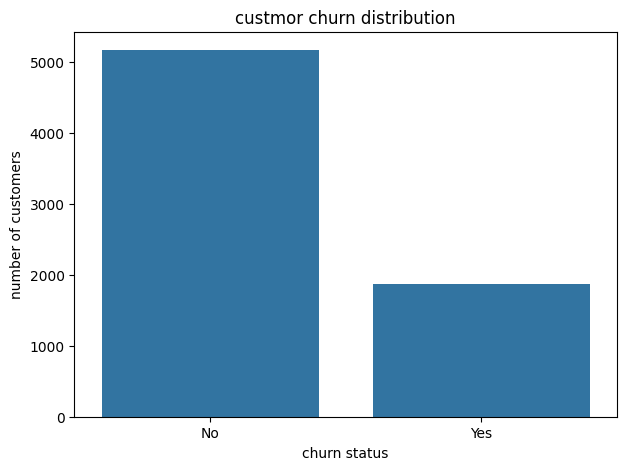

In [108]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Churn")
plt.title("custmor churn distribution")
plt.xlabel("churn status")
plt.ylabel("number of customers")

plt.show()

Text(0, 0.5, 'number')

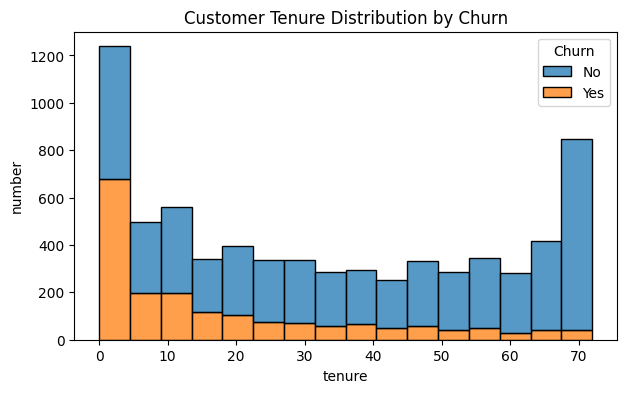

In [109]:
plt.figure(figsize=(7, 4))

sns.histplot(data=df, x="tenure", hue="Churn", multiple="stack")

plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("tenure")
plt.ylabel("number")

In [110]:
df['tenure_group'] = pd.cut(df['tenure'], bins=[-1, 12, 24, 36, 48, 60, 72], labels=["0-12", "13-24", "25-36", "37-48", "49-60", "61-72"])

Churn_rate = df.groupby("tenure_group", observed=False)["Churn"].apply(lambda x: (x == "Yes").mean()*100)

print(Churn_rate)

tenure_group
0-12     47.438243
13-24    28.710938
25-36    21.634615
37-48    19.028871
49-60    14.423077
61-72     6.609808
Name: Churn, dtype: float64


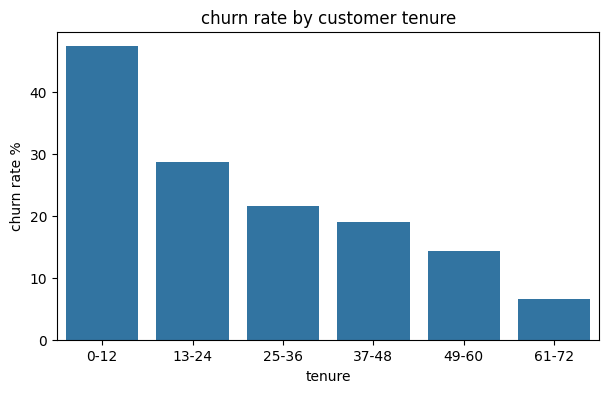

In [111]:
plt.figure(figsize=(7, 4))
sns.barplot(x= Churn_rate.index, y= Churn_rate.values)

plt.title("churn rate by customer tenure")
plt.xlabel("tenure")
plt.ylabel("churn rate %")

plt.show()

In [112]:
contract_churn = df.groupby("Contract")["Churn"].apply(lambda x: (x == "Yes").mean()*100)
print(contract_churn)

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn, dtype: float64


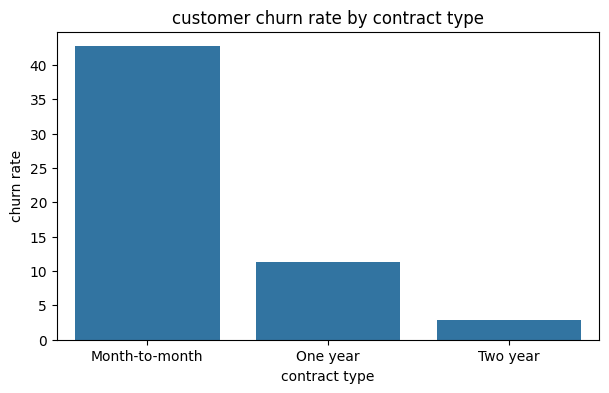

In [113]:
plt.figure(figsize=(7, 4))
sns.barplot(x=contract_churn.index, y= contract_churn.values)

plt.title("customer churn rate by contract type")
plt.xlabel("contract type")
plt.ylabel("churn rate")

plt.show()

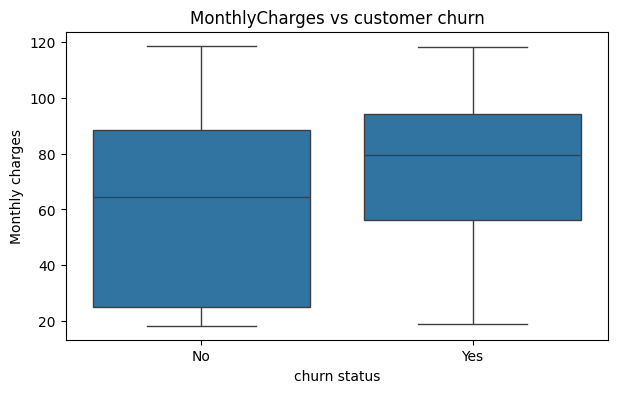

In [114]:
plt.figure(figsize=(7, 4))

sns.boxplot(data=df,x="Churn", y="MonthlyCharges" )

plt.title("MonthlyCharges vs customer churn")
plt.xlabel("churn status")
plt.ylabel("Monthly charges")

plt.show()

In [115]:
df.groupby("Churn")["MonthlyCharges"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,61.265124,31.092648,18.25,25.10,64.425,88.4,118.75
Yes,1869.0,74.441332,24.666053,18.85,56.15,79.650,94.2,118.35


In [116]:
df = df.drop(columns=["customerID", "tenure_group"])
x = df.drop("Churn", axis=1)
y = df["Churn"]

print("Features shape: ", x.shape)
print("Target shape: ", y.shape)

Features shape:  (7043, 19)
Target shape:  (7043,)


In [117]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state= 42, stratify=y)

print("x_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

x_train: (5634, 19)
X_test: (1409, 19)
y_train: (5634,)
y_test: (1409,)


In [118]:
numercal_features = X_train.select_dtypes(include=["int64", "float64"]).columns

catigorical_features = X_train.select_dtypes(include=["object"]).columns

print("numercal_features:")
print(list(numercal_features))

print("\nCatigorical_features:")
print(list(catigorical_features))


numercal_features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Catigorical_features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [119]:
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(handle_unknown= "ignore", sparse_output= False)

X_train_encoded = encoder.fit_transform(X_train[catigorical_features])

X_test_encoded = encoder.transform(X_test[catigorical_features])

print("Encoded training shape:", X_train_encoded.shape)
print("Encoded testing shape:", X_test_encoded.shape)


Encoded training shape: (5634, 41)
Encoded testing shape: (1409, 41)


In [120]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train[numercal_features])

X_test_scaled = scaler.transform(X_test[numercal_features])

print("Scaled Training Shape:", X_train_scaled.shape)
print("Scaled Testing Shape:", X_test_scaled.shape)

Scaled Training Shape: (5634, 4)
Scaled Testing Shape: (1409, 4)


In [121]:
X_train_final = np.concatenate([X_train_scaled, X_train_encoded], axis=1)

X_test_final = np.concatenate([X_test_scaled, X_test_encoded], axis=1)

print("Final training shape:", X_train_final.shape)
print("Final testing shape:", X_test_final.shape)

Final training shape: (5634, 45)
Final testing shape: (1409, 45)


In [122]:
y_train = y_train.map({"No": 0, "Yes": 1})
y_test = y_test.map({"No": 0, "Yes": 1})

print(y_train.value_counts())
print(y_test.value_counts())

Churn
0    4139
1    1495
Name: count, dtype: int64
Churn
0    1035
1     374
Name: count, dtype: int64


In [123]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(random_state=42)

model.fit(X_train_final, y_train)

print("model trained successfuly")

model trained successfuly


In [124]:
y_pred = model.predict(X_test_final)

print("first 20 predicition:")
print(y_pred[:20])

print("\nActual values:")
print(y_test.values[:20])

first 20 predicition:
[0 1 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 0]

Actual values:
[0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0]


In [125]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.8055358410220014
Precision: 0.6572327044025157
Recall: 0.5588235294117647
F1 Score: 0.6040462427745664


[[926 109]
 [165 209]]


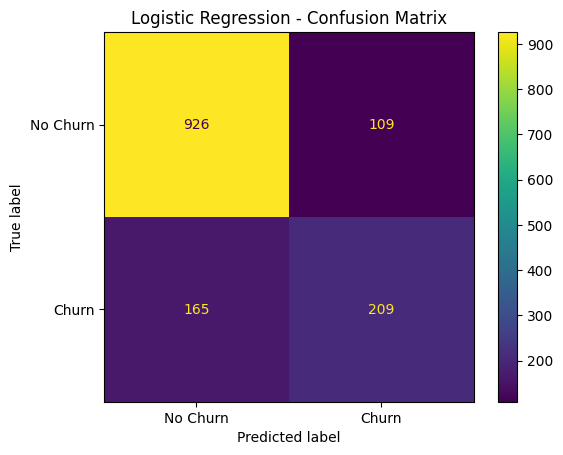

In [126]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
).plot()

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [127]:
model_balanced = LogisticRegression(
    random_state=42,
    class_weight="balanced"
)

model_balanced.fit(X_train_final, y_train)

y_pred_balanced = model_balanced.predict(X_test_final)

In [128]:
print("Accuracy:", accuracy_score(y_test, y_pred_balanced))
print("Precision:", precision_score(y_test, y_pred_balanced))
print("Recall:", recall_score(y_test, y_pred_balanced))
print("F1 Score:", f1_score(y_test, y_pred_balanced))

Accuracy: 0.7381121362668559
Precision: 0.504302925989673
Recall: 0.7834224598930482
F1 Score: 0.6136125654450262


In [129]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_final, y_train)

y_pred_rf = rf_model.predict(X_test_final)

In [130]:
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))

Accuracy: 0.7835344215755855
Precision: 0.6185567010309279
Recall: 0.48128342245989303
F1 Score: 0.5413533834586466


In [131]:
rf_balanced = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_balanced.fit(X_train_final, y_train)

y_pred_rf_balanced = rf_balanced.predict(X_test_final)

In [132]:
print("Accuracy:", accuracy_score(y_test, y_pred_rf_balanced))
print("Precision:", precision_score(y_test, y_pred_rf_balanced))
print("Recall:", recall_score(y_test, y_pred_rf_balanced))
print("F1 Score:", f1_score(y_test, y_pred_rf_balanced))

Accuracy: 0.7828246983676366
Precision: 0.6188811188811189
Recall: 0.4732620320855615
F1 Score: 0.5363636363636364


In [133]:
encoded_feature_names = encoder.get_feature_names_out(catigorical_features)

all_feature_names = list(numercal_features) + list(encoded_feature_names)

feature_importance = pd.DataFrame({"Feature": all_feature_names, "Importance": rf_model.feature_importances_})

feature_importance = feature_importance.sort_values(by="Importance", ascending=False)

print(feature_importance.head(15))

                           Feature  Importance
3                     TotalCharges    0.157102
1                           tenure    0.142508
2                   MonthlyCharges    0.137807
36         Contract_Month-to-month    0.053097
18               OnlineSecurity_No    0.032972
43  PaymentMethod_Electronic check    0.030101
27                  TechSupport_No    0.028003
16     InternetService_Fiber optic    0.026064
0                    SeniorCitizen    0.019436
21                 OnlineBackup_No    0.018395
5                      gender_Male    0.018052
4                    gender_Female    0.017777
38               Contract_Two year    0.016358
40            PaperlessBilling_Yes    0.016206
24             DeviceProtection_No    0.015680


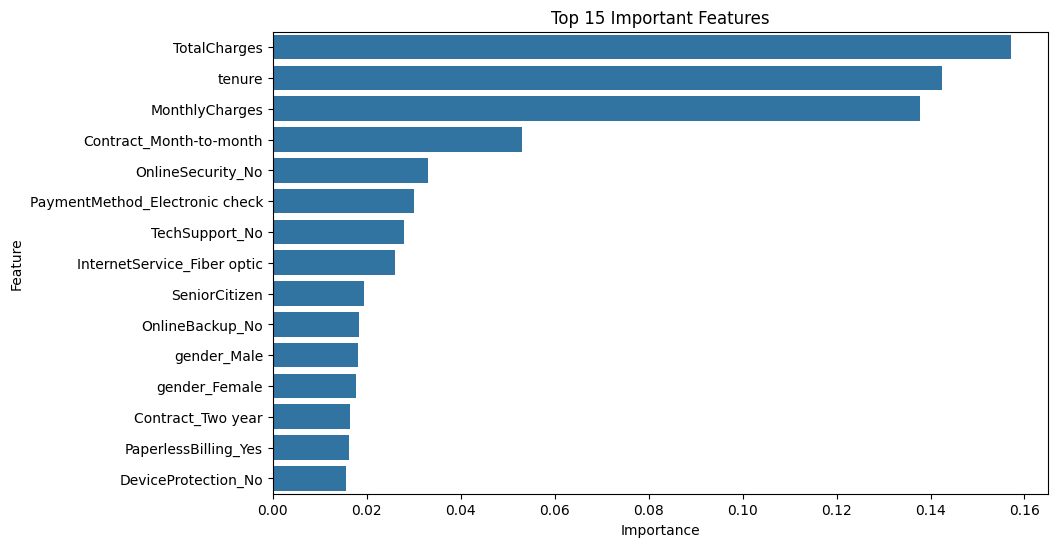

In [134]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [136]:
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20],
    "min_sampels_split": [2, 5],
    "min_sampels_leaf": [1, 2]
}

In [139]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    random_state = 42,
    n_jobs = -1
)

In [151]:
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

In [152]:
grid_search = GridSearchCV(
    estimator = rf,
    param_grid = param_grid,
    scoring = "f1",
    cv = 5,
    n_jobs = -1,
    verbose=1
)

In [153]:
grid_search.fit(X_train_final, y_train)

Fitting 5 folds for each of 36 candidates, totalling 180 fits


GridSearchCV(cv=5, estimator=RandomForestClassifier(n_jobs=-1, random_state=42),
             n_jobs=-1,
             param_grid={'max_depth': [None, 10, 20],
                         'min_samples_leaf': [1, 2],
                         'min_samples_split': [2, 5],
                         'n_estimators': [100, 200, 300]},
             scoring='f1', verbose=1)

In [154]:
best_rf = grid_search.best_estimator_

print("best parameters:")
print(grid_search.best_params_)

print("\nBest cv f1 score")
print(grid_search.best_score_)

best parameters:
{'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}

Best cv f1 score
0.5776449837826074


In [155]:
y_pred_best = best_rf.predict(X_test_final)

In [156]:
print("Accuracy:", accuracy_score(y_test, y_pred_best))
print("Precision:", precision_score(y_test, y_pred_best))
print("Recall:", recall_score(y_test, y_pred_best))
print("F1 Score:", f1_score(y_test, y_pred_best))

Accuracy: 0.8076650106458482
Precision: 0.6710963455149501
Recall: 0.5401069518716578
F1 Score: 0.5985185185185186


In [157]:
y_proba = model_balanced.predict_proba(X_test_final)[:, 1]
print(y_proba[:10])

[0.11772432 0.85189963 0.14625052 0.66023441 0.06044972 0.80508058
 0.69675764 0.29176099 0.00896026 0.65222865]


In [159]:
from sklearn.model_selection import train_test_split

X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train_final,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

In [160]:
print(X_train_new.shape)
print(X_val.shape)

(4507, 45)
(1127, 45)


In [162]:
from sklearn.linear_model import LogisticRegression

validation_model = LogisticRegression(
    random_state=42,
    class_weight="balanced"
)
validation_model.fit(X_train_new, y_train_new)

LogisticRegression(class_weight='balanced', random_state=42)

In [163]:
y_val_proba = validation_model.predict(X_val)[:, 1]

print(y_val_proba[:10])

IndexError: too many indices for array: array is 1-dimensional, but 2 were indexed

In [164]:
print(X_train_final.shape)
print(type(X_train_final))

(5634, 45)
<class 'numpy.ndarray'>


In [165]:
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)
print("Predictions:", validation_model.predict_proba(X_val).shape)

X_val: (1127, 45)
y_val: (1127,)
Predictions: (1127, 2)


In [166]:
y_val_proba = validation_model.predict_proba(X_val)[:, 1]

print(y_val_proba[:10])

[0.43248933 0.04823196 0.12945521 0.34566515 0.47740729 0.09584812
 0.40205283 0.04082845 0.04457668 0.46641167]


In [171]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

thresholds = [0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]

results = []

for threshold in thresholds:
  y_val_pred = (y_val_proba >= threshold).astype(int)

  precision = precision_score(y_val, y_val_pred)
  recall = recall_score(y_val, y_val_pred)
  f1 = f1_score(y_val, y_val_pred)

  results.append({
      "threshold": thresholds,
      "precision": precision,
      "recall": recall,
      "f1 score": f1
  })

  results_df = pd.DataFrame(results)

  print(results_df.round(3))


                                threshold  precision  recall  f1 score
0  [0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]      0.422   0.916     0.578
                                threshold  precision  recall  f1 score
0  [0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]      0.422   0.916     0.578
1  [0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]      0.437   0.893     0.587
                                threshold  precision  recall  f1 score
0  [0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]      0.422   0.916     0.578
1  [0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]      0.437   0.893     0.587
2  [0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]      0.464   0.870     0.605
                                threshold  precision  recall  f1 score
0  [0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]      0.422   0.916     0.578
1  [0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]      0.437   0.893     0.587
2  [0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]      0.464   0.870     0.605
3  [0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]      0.493   0.826     0.618
      

In [174]:
best_threshold = 0.55

y_val_pred_final = (y_val_proba >= best_threshold).astype(int)

from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(y_val, y_val_pred_final))
print(confusion_matrix(y_val, y_val_pred_final))

              precision    recall  f1-score   support

           0       0.90      0.77      0.83       828
           1       0.55      0.76      0.63       299

    accuracy                           0.77      1127
   macro avg       0.72      0.76      0.73      1127
weighted avg       0.80      0.77      0.78      1127

[[640 188]
 [ 73 226]]


In [176]:
final_model = LogisticRegression(
    random_state = 42,
    class_weight = "balanced"
)

final_model.fit(X_train_final, y_train)

y_test_proba = final_model.predict_proba(X_test_final)[:, 1]

best_threshold = 0.55

y_test_pred = (y_test_proba >= best_threshold).astype(int)

print(classification_report(y_test, y_test_pred))
print(confusion_matrix(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       0.89      0.75      0.82      1035
           1       0.52      0.75      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.80      0.75      0.76      1409

[[780 255]
 [ 93 281]]
